# ch05_1. CIFAR-10 ResNet18 학습과 평가

## 개요

- Residual Connection(레지듀얼 커넥션, 잔차 연결)의 원리를 이해합니다.
- 훈련·검증·시험 데이터의 역할을 구분합니다.

## 공통 설정

데이터·모델·이미지 폴더 위치를 지정합니다.

In [1]:
from pathlib import Path

DATA_DIR = Path("data")
MODEL_DIR = Path("models")
PNG_DIR = Path("png")

DATA_DIR.mkdir(exist_ok=True)

MODEL_DIR.mkdir(exist_ok=True)
PNG_DIR.mkdir(exist_ok=True)

print("데이터 폴더:", DATA_DIR)
print("모델 폴더  :", MODEL_DIR)
print("이미지 폴더:", PNG_DIR)


데이터 폴더: data
모델 폴더  : models
이미지 폴더: png


## 공통 import

In [2]:
import random
import time
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.models import resnet18

### 1) 난수 시드 고정

```text
CIFAR-10 데이터 준비
→ 훈련·검증·시험 데이터 구성
→ CIFAR-10용 ResNet18 생성
→ Residual Block과 Shape 확인
→ 모델 학습
→ 최고 모델 저장
→ 시험 세트 최종 평가
→ 혼동행렬·클래스별 정확도
→ 예측 결과·오답 분석
```

일반적인 CNN Block(씨엔엔 블록, 합성곱 계층 묶음)은 입력 $\mathbf{x}$를 여러 계층에 통과시킨 결과 $F(\mathbf{x})$를 다음 계층으로 전달합니다.

```text
일반 블록
x → Conv → BatchNorm → ReLU → Conv → BatchNorm → F(x)
```

Residual Block(레지듀얼 블록, 잔차 블록)은 원래 입력 $\mathbf{x}$를 변환 결과에 더합니다.

```text
 ┌──────────── x ────────────┐
 │ ↓
x → Conv → BN → ReLU → Conv → BN → F(x) → F(x) + x → ReLU
```

\[
\mathbf{y}=F(\mathbf{x};\mathbf{W})+\mathbf{x}
\]

- $\mathbf{x}$: 블록에 들어온 원래 특징
- $F(\mathbf{x};\mathbf{W})$: 합성곱 계층이 가중치 $\mathbf{W}$로 학습한 변화량
- $\mathbf{y}$: 기존 특징과 새 특징을 더한 출력

> **ResNet은 출력 전체를 새로 만드는 대신, 입력에 더할 변화량을 학습합니다.**

입력과 $F(\mathbf{x})$의 Shape(셰이프, 텐서 크기)가 다르면 바로 더할 수 없습니다. 이때 Downsample(다운샘플, 크기와 채널을 맞추는 변환)이 입력의 Shape를 조정합니다.

- `torch`: 텐서 연산과 모델 학습
- `torch.nn`: 신경망 계층과 손실함수
- `torchvision.datasets`: CIFAR-10 데이터셋
- `torchvision.transforms`: 이미지 전처리와 데이터 증강
- `torchvision.models.resnet18`: ResNet18 모델 생성
- `DataLoader`: 미니배치 구성
- `Subset`: 지정한 인덱스만 선택

- `QUICK_RUN = True`: 일부 데이터와 3 Epoch로 코드 흐름 확인
- `QUICK_RUN = False`: 전체 데이터와 40 Epoch로 본 학습

빠른 실행 결과는 최종 정확도 비교용이 아닙니다.

In [3]:
SEED = 42

random.seed(SEED)

np.random.seed(SEED)

torch.manual_seed(SEED)

### 2) GPU 난수 시드 고정

In [4]:
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

### 3) 실행 장치와 학습 설정

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

QUICK_RUN = True

BATCH_SIZE = 128

EPOCHS = 3 if QUICK_RUN else 40

LEARNING_RATE = 0.1

MOMENTUM = 0.9

WEIGHT_DECAY = 5e-4

PATIENCE = 3 if QUICK_RUN else 10

VALIDATION_SIZE = 5_000

NUM_WORKERS = 2

CIFAR10_MEAN = (0.4914, 0.4822, 0.4465)

CIFAR10_STD = (0.2470, 0.2435, 0.2616)

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck",
]

class_names_ko = [
    "비행기", "자동차", "새", "고양이", "사슴",
    "개", "개구리", "말", "배", "트럭",
]

print("PyTorch 버전:", torch.__version__)

print("실행 장치:", device)

print("Quick Run:", QUICK_RUN)

print("Epoch:", EPOCHS)

PyTorch 버전: 2.13.0+cu130
실행 장치: cuda
Quick Run: True
Epoch: 3


### 4) 변환과 데이터 분할

CIFAR-10 공식 훈련 데이터 50,000개에서 검증 데이터 5,000개를 분리합니다.

```text
공식 훈련 데이터 50,000개
├─ 훈련 데이터 45,000개
└─ 검증 데이터 5,000개

공식 시험 데이터 10,000개
└─ 최종 시험 데이터 10,000개
```

```text
RandomCrop
→ RandomHorizontalFlip
→ ToTensor
→ Normalize
```

훈련 데이터에만 무작위 변형을 적용하여 다양한 이미지를 학습하게 합니다.

```text
ToTensor
→ Normalize
```

검증과 시험 데이터는 성능을 공정하게 측정해야 하므로 무작위 변형을 적용하지 않습니다.

In [6]:
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD),
])

evaluation_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD),
])

train_source = datasets.CIFAR10(
    root=str(DATA_DIR / "torchvision"), train=True, download=True, transform=train_transform
)

validation_source = datasets.CIFAR10(
    root=str(DATA_DIR / "torchvision"), train=True, download=False, transform=evaluation_transform
)

test_dataset = datasets.CIFAR10(
    root=str(DATA_DIR / "torchvision"), train=False, download=True, transform=evaluation_transform
)

generator = torch.Generator().manual_seed(SEED)

indices = torch.randperm(len(train_source), generator=generator).tolist()

train_indices = indices[:-VALIDATION_SIZE]

validation_indices = indices[-VALIDATION_SIZE:]

100.0%


### 5) 빠른 실행용 데이터 축소

In [7]:
if QUICK_RUN:
    train_indices = train_indices[:5_000]
    validation_indices = validation_indices[:1_000]
    test_dataset = Subset(test_dataset, range(2_000))

### 6) 학습·검증 Subset 만들기

In [8]:
train_dataset = Subset(train_source, train_indices)

validation_dataset = Subset(validation_source, validation_indices)

### 7) DataLoader 생성 함수

In [9]:
def make_loader(dataset, shuffle):
    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
    )

### 8) DataLoader 준비

In [10]:
train_loader = make_loader(train_dataset, shuffle=True)

validation_loader = make_loader(validation_dataset, shuffle=False)

test_loader = make_loader(test_dataset, shuffle=False)

print("훈련 데이터:", len(train_dataset))

print("검증 데이터:", len(validation_dataset))

print("시험 데이터:", len(test_dataset))

훈련 데이터: 5000
검증 데이터: 1000
시험 데이터: 2000


### 9) 배치 데이터 확인

정규화된 이미지는 그대로 표시하면 색상이 어색하게 보입니다.

정규화 식은 다음과 같습니다.

\[
\mathbf{x}_{norm}=\frac{\mathbf{x}-\boldsymbol{\mu}}{\boldsymbol{\sigma}}
\]

화면에 표시할 때는 역변환합니다.

\[
\mathbf{x}=\mathbf{x}_{norm}\boldsymbol{\sigma}+\boldsymbol{\mu}
\]

- $\boldsymbol{\mu}$: 채널별 평균
- $\boldsymbol{\sigma}$: 채널별 표준편차

/tmp/ipykernel_101250/2464975751.py:19: UserWarning: Glyph 49324 (\N{HANGUL SYLLABLE SA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_101250/2464975751.py:19: UserWarning: Glyph 49844 (\N{HANGUL SYLLABLE SEUM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_101250/2464975751.py:19: UserWarning: Glyph 47568 (\N{HANGUL SYLLABLE MAL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_101250/2464975751.py:19: UserWarning: Glyph 53944 (\N{HANGUL SYLLABLE TEU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_101250/2464975751.py:19: UserWarning: Glyph 47085 (\N{HANGUL SYLLABLE REOG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_101250/2464975751.py:19: UserWarning: Glyph 48708 (\N{HANGUL SYLLABLE BI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_101250/2464975751.py:19: UserWarning: Glyph 54665 (\N{HANGUL SYLLABLE HAENG}) missing from font(s) DejaVu San

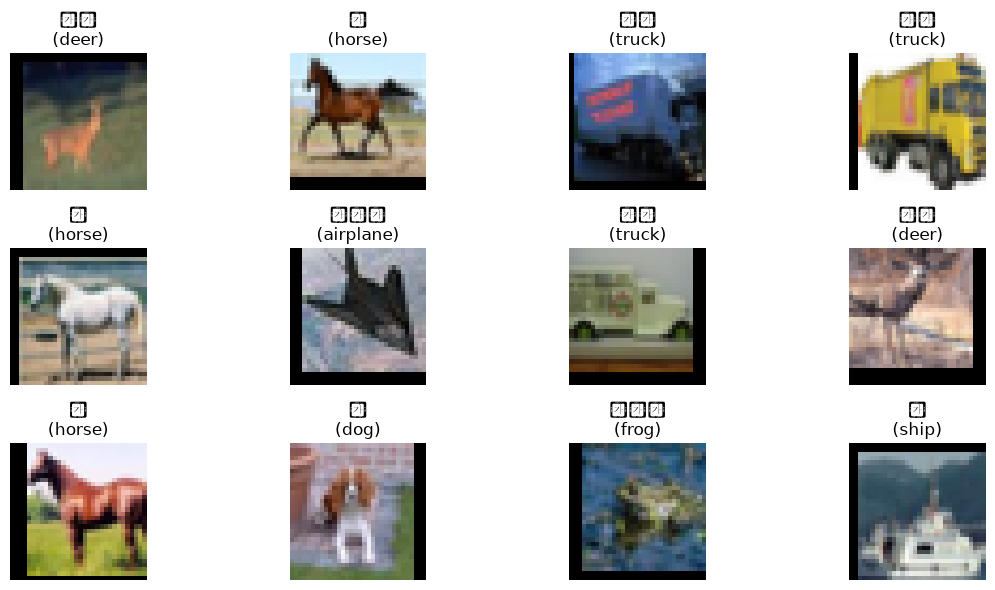

In [11]:
def denormalize_image(image):
    mean = torch.tensor(CIFAR10_MEAN).view(3, 1, 1)
    std = torch.tensor(CIFAR10_STD).view(3, 1, 1)
    return (image.cpu() * std + mean).clamp(0, 1)

sample_images, sample_labels = next(iter(train_loader))

plt.figure(figsize=(12, 6))

for index in range(12):
    image = denormalize_image(sample_images[index]).permute(1, 2, 0)
    label = sample_labels[index].item()

    plt.subplot(3, 4, index + 1)
    plt.imshow(image)
    plt.title(f"{class_names_ko[label]}\n({class_names[label]})")
    plt.axis("off")

plt.tight_layout()

plt.show()

### 10) 모델 구성

기본 `resnet18()`은 ImageNet(이미지넷, 대규모 이미지 데이터셋)의 큰 이미지를 기준으로 설계되었습니다.

```text
기본 입력부
7×7 Conv, stride=2
→ 3×3 MaxPool, stride=2
```

32×32 CIFAR-10 이미지에 그대로 적용하면 공간 크기가 초반에 너무 빠르게 줄어듭니다.

```text
CIFAR-10용 입력부
3×3 Conv, stride=1
→ MaxPool 제거
```

마지막 출력층은 CIFAR-10의 10개 클래스에 맞춥니다.

`weights=None`은 사전학습 가중치를 사용하지 않고 처음부터 학습한다는 뜻입니다.

In [12]:
def create_cifar10_resnet18(num_classes=10):
    model = resnet18(weights=None, num_classes=num_classes)

    # CIFAR-10의 32×32 이미지에 맞게 입력부 수정
    model.conv1 = nn.Conv2d(
        3, 64, kernel_size=3, stride=1, padding=1, bias=False
    )
    model.maxpool = nn.Identity()

    return model

model = create_cifar10_resnet18().to(device)

print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): Identity()
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(

### 11) 모델 파라미터 확인

ResNet18의 첫 번째 BasicBlock(베이식 블록, 기본 잔차 블록)은 입력과 출력 Shape가 같으므로 입력을 그대로 더합니다.

`layer2[0]`은 채널 수와 공간 크기가 바뀌므로 Downsample 경로를 사용합니다.

```text
입력 : [N, 3, 32, 32]
conv1 : [N, 64, 32, 32]
layer1 : [N, 64, 32, 32]
layer2 : [N, 128, 16, 16]
layer3 : [N, 256, 8, 8]
layer4 : [N, 512, 4, 4]
avgpool : [N, 512, 1, 1]
flatten : [N, 512]
fc : [N, 10]
```

공간 크기는 줄어들고 채널 수는 증가합니다.

```text
공간 크기: 32 → 16 → 8 → 4 → 1
채널 수 : 64 → 128 → 256 → 512
```

In [13]:
print("===== layer1[0] =====")

print(model.layer1[0])

print("Downsample:", model.layer1[0].downsample)

print("\n===== layer2[0] =====")

print(model.layer2[0])

print("Downsample:", model.layer2[0].downsample)

x = torch.randn(2, 3, 32, 32, device=device)

model.eval()

with torch.inference_mode():
    x = model.conv1(x)
    print("\nconv1  :", x.shape)

    x = model.relu(model.bn1(x))
    x = model.maxpool(x)

    x = model.layer1(x)
    print("layer1 :", x.shape)

    x = model.layer2(x)
    print("layer2 :", x.shape)

    x = model.layer3(x)
    print("layer3 :", x.shape)

    x = model.layer4(x)
    print("layer4 :", x.shape)

    x = model.avgpool(x)
    print("avgpool:", x.shape)

    x = torch.flatten(x, 1)
    print("flatten:", x.shape)

    logits = model.fc(x)
    print("logits :", logits.shape)

parameter_count = sum(parameter.numel() for parameter in model.parameters())

print(f"\n전체 파라미터: {parameter_count:,}개")

===== layer1[0] =====
BasicBlock(
  (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
)
Downsample: None

===== layer2[0] =====
BasicBlock(
  (conv1): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (conv2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (downsample): Sequential(
    (0): Conv2d(64, 128, kernel_size=(1, 1), stride=(2, 2), bias=

### 12) 학습 함수 정의

모델은 각 클래스의 Logit(로짓, 정규화되지 않은 원시 점수)을 출력합니다.

`nn.CrossEntropyLoss()`는 Logit과 정답 클래스 번호를 받아 다중분류 손실을 계산합니다. 모델 출력에 Softmax(소프트맥스, 점수를 확률로 변환하는 함수)를 미리 적용하지 않습니다.

\[
L=-\frac{1}{N}\sum_{i=1}^{N}\log p_{i,y_i}
\]

- $N$: 미니배치의 이미지 수
- $y_i$: $i$번째 이미지의 실제 클래스
- $p_{i,y_i}$: 실제 클래스에 대한 예측 확률

정확도는 전체 이미지 중 정답을 맞힌 비율입니다.

\[
\text{Accuracy}
=\frac{\text{Correct Predictions}}{\text{Total Samples}}
\]

```text
model.train()
→ Forward
→ Loss 계산
→ 기울기 초기화
→ Backpropagation
→ 가중치 갱신
```

```text
model.eval()
→ torch.inference_mode()
→ Forward
→ Loss·Accuracy 계산
```

In [14]:
def train_one_epoch(model, data_loader, loss_function, optimizer):
    model.train()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, labels in data_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(images)
        loss = loss_function(logits, labels)

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_samples += batch_size

    average_loss = total_loss / total_samples
    accuracy = total_correct / total_samples

    return average_loss, accuracy

### 13) 평가 함수 정의

In [15]:
def evaluate(model, data_loader, loss_function):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.inference_mode():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            loss = loss_function(logits, labels)

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            total_correct += (logits.argmax(dim=1) == labels).sum().item()
            total_samples += batch_size

    average_loss = total_loss / total_samples
    accuracy = total_correct / total_samples

    return average_loss, accuracy

### 14) Loss·Optimizer·Scheduler 설정

- `nn.CrossEntropyLoss()`
- 다중분류 문제에 사용
- 모델은 10개 클래스의 Logit을 출력

SGD(에스지디, 확률적 경사하강법)에 Momentum(모멘텀, 이전 이동 방향 활용)과 Weight Decay(웨이트 디케이, 가중치 감쇠)를 적용합니다.

```text
SGD
+ Momentum
+ Weight Decay
```

`CosineAnnealingLR`(코사인 어닐링 러닝 레이트, 코사인 곡선형 학습률 조정기)은 Epoch가 진행될수록 학습률을 부드럽게 낮춥니다.

In [16]:
loss_function = nn.CrossEntropyLoss()

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=LEARNING_RATE,
    momentum=MOMENTUM,
    weight_decay=WEIGHT_DECAY,
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS,
    eta_min=1e-4,
)

BEST_MODEL_PATH = MODEL_DIR / "ch05_1_best_cifar10_resnet18.pt"

print("손실함수:", loss_function)

print("Optimizer:", optimizer.__class__.__name__)

print("Scheduler:", scheduler.__class__.__name__)

print("저장 경로:", BEST_MODEL_PATH)

손실함수: CrossEntropyLoss()
Optimizer: SGD
Scheduler: CosineAnnealingLR
저장 경로: models/ch05_5_best_cifar10_resnet18.pt


### 15) 학습 기록과 최적 모델 준비

각 Epoch(에포크, 전체 훈련 데이터 1회 학습)에서 다음 값을 기록합니다.

- 훈련 손실
- 훈련 정확도
- 검증 손실
- 검증 정확도
- 학습률

검증 정확도가 가장 높아질 때 체크포인트를 저장합니다.

> **시험 데이터는 모델 선택에 사용하지 않습니다.**

In [17]:
history = {
    "train_loss": [],
    "train_accuracy": [],
    "validation_loss": [],
    "validation_accuracy": [],
    "learning_rate": [],
}

best_validation_accuracy = 0.0

best_epoch = 0

epochs_without_improvement = 0

start_time = time.time()

### 16) 모델 학습과 최고 모델 저장

In [18]:
for epoch in range(EPOCHS):
    current_lr = optimizer.param_groups[0]["lr"]

    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, loss_function, optimizer
    )

    validation_loss, validation_accuracy = evaluate(
        model, validation_loader, loss_function
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["validation_loss"].append(validation_loss)
    history["validation_accuracy"].append(validation_accuracy)
    history["learning_rate"].append(current_lr)

    if validation_accuracy > best_validation_accuracy:
        best_validation_accuracy = validation_accuracy
        best_epoch = epoch + 1
        epochs_without_improvement = 0

        checkpoint = {
            "model_name": "cifar10_resnet18",
            "model_state_dict": model.state_dict(),
            "num_classes": 10,
            "class_names": class_names,
            "cifar10_mean": CIFAR10_MEAN,
            "cifar10_std": CIFAR10_STD,
            "best_epoch": best_epoch,
            "best_validation_accuracy": best_validation_accuracy,
        }

        torch.save(checkpoint, BEST_MODEL_PATH)
    else:
        epochs_without_improvement += 1

    scheduler.step()

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train Loss {train_loss:.4f} | "
        f"Train Acc {train_accuracy * 100:.2f}% | "
        f"Val Loss {validation_loss:.4f} | "
        f"Val Acc {validation_accuracy * 100:.2f}% | "
        f"LR {current_lr:.6f}"
    )

    if epochs_without_improvement >= PATIENCE:
        print(f"Early Stopping: {PATIENCE}개 Epoch 동안 성능 개선 없음")
        break

Epoch 01/3 | Train Loss 3.4618 | Train Acc 11.48% | Val Loss 2.4061 | Val Acc 14.80% | LR 0.100000
Epoch 02/3 | Train Loss 2.2561 | Train Acc 15.02% | Val Loss 2.2595 | Val Acc 18.50% | LR 0.075025
Epoch 03/3 | Train Loss 2.1182 | Train Acc 18.76% | Val Loss 2.1085 | Val Acc 21.40% | LR 0.025075


### 17) 최고 모델 불러오기

In [19]:
best_checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=True,
)

model.load_state_dict(best_checkpoint["model_state_dict"])

model.to(device)

elapsed_minutes = (time.time() - start_time) / 60

print("\n최고 검증 Epoch:", best_epoch)

print(f"최고 검증 정확도: {best_validation_accuracy * 100:.2f}%")

print(f"전체 학습 시간: {elapsed_minutes:.2f}분")

print("최고 모델 저장:", BEST_MODEL_PATH)


최고 검증 Epoch: 3
최고 검증 정확도: 21.40%
전체 학습 시간: 0.16분
최고 모델 저장: models/ch05_5_best_cifar10_resnet18.pt


### 18) 학습 곡선 시각화

- 훈련 손실과 검증 손실이 함께 감소하면 안정적인 학습
- 훈련 손실만 감소하고 검증 손실이 증가하면 과적합 가능성

- 훈련 정확도와 검증 정확도의 차이가 작으면 일반화가 양호
- 두 정확도의 차이가 계속 커지면 과적합 가능성

Cosine Annealing(코사인 어닐링)은 학습률을 갑자기 낮추지 않고 부드럽게 감소시킵니다.

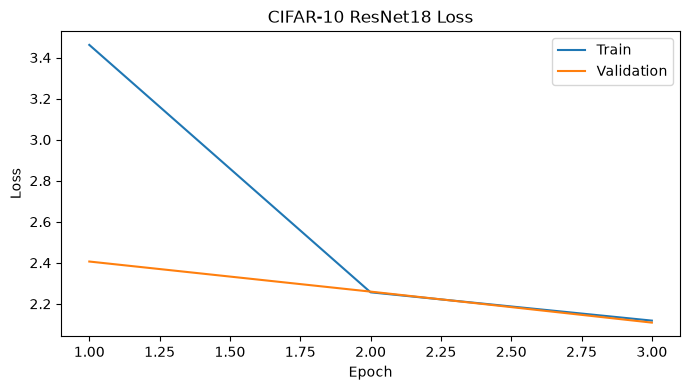

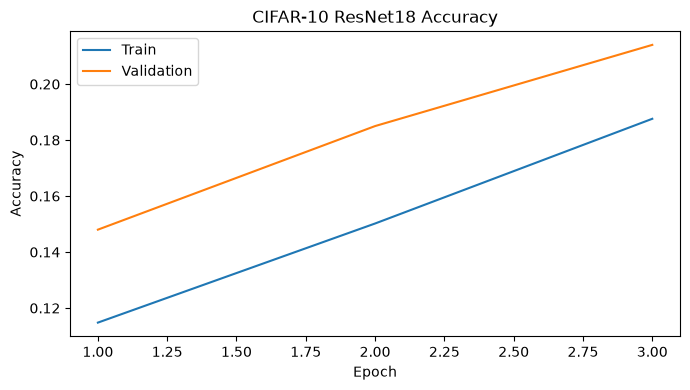

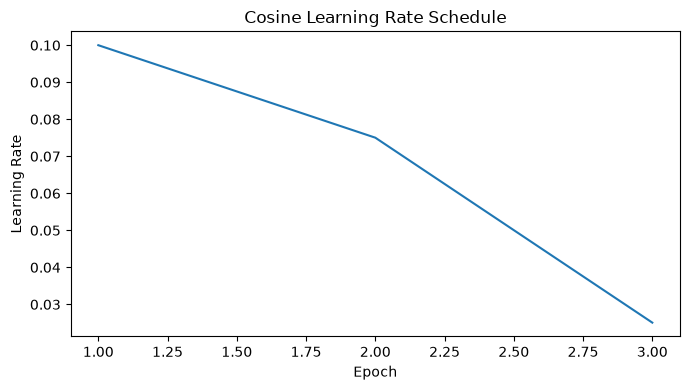

In [20]:
epochs_completed = len(history["train_loss"])

epoch_axis = range(1, epochs_completed + 1)

plt.figure(figsize=(7, 4))

plt.plot(epoch_axis, history["train_loss"], label="Train")

plt.plot(epoch_axis, history["validation_loss"], label="Validation")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title("CIFAR-10 ResNet18 Loss")

plt.legend()

plt.tight_layout()

plt.show()

plt.figure(figsize=(7, 4))

plt.plot(epoch_axis, history["train_accuracy"], label="Train")

plt.plot(epoch_axis, history["validation_accuracy"], label="Validation")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.title("CIFAR-10 ResNet18 Accuracy")

plt.legend()

plt.tight_layout()

plt.show()

plt.figure(figsize=(7, 4))

plt.plot(epoch_axis, history["learning_rate"])

plt.xlabel("Epoch")

plt.ylabel("Learning Rate")

plt.title("Cosine Learning Rate Schedule")

plt.tight_layout()

plt.show()

### 19) 테스트 평가와 예측 수집

```text
Train Set
→ 가중치 학습

Validation Set
→ 최고 모델 선택

Test Set
→ 최종 일반화 성능 평가
```

시험 데이터 전체에서 다음 값을 수집합니다.

- 실제 클래스
- 예측 클래스
- 예측 확률
- 화면 표시용 이미지

`torch.softmax()`는 결과를 분석할 때만 Logit을 확률로 변환합니다.

In [21]:
test_loss, test_accuracy = evaluate(model, test_loader, loss_function)

print(f"시험 손실: {test_loss:.4f}")

print(f"시험 정확도: {test_accuracy * 100:.2f}%")

def collect_predictions(model, data_loader):
    model.eval()

    all_images = []
    all_labels = []
    all_predictions = []
    all_confidences = []

    with torch.inference_mode():
        for images, labels in data_loader:
            logits = model(images.to(device))
            probabilities = torch.softmax(logits, dim=1)
            confidences, predictions = probabilities.max(dim=1)

            all_images.append(images.cpu())
            all_labels.append(labels.cpu())
            all_predictions.append(predictions.cpu())
            all_confidences.append(confidences.cpu())

    return (
        torch.cat(all_images),
        torch.cat(all_labels),
        torch.cat(all_predictions),
        torch.cat(all_confidences),
    )

test_images, test_labels, test_predictions, test_confidences = (
    collect_predictions(model, test_loader)
)

print("예측 이미지 수:", len(test_predictions))

시험 손실: 2.0745
시험 정확도: 21.65%
예측 이미지 수: 2000


### 20) Confusion Matrix 준비

Confusion Matrix(컨퓨전 매트릭스, 혼동행렬)는 실제 클래스와 예측 클래스의 관계를 나타냅니다.

```text
행 → 실제 클래스
열 → 예측 클래스
```

- 대각선: 올바르게 분류한 이미지 수
- 대각선 이외: 다른 클래스로 잘못 분류한 이미지 수

클래스별 정확도는 다음과 같습니다.

\[
\text{Class Accuracy}_k
=\frac{\text{Class }k\text{ Correct}}{\text{Class }k\text{ Total}}
\]

In [22]:
def build_confusion_matrix(true_labels, predicted_labels, num_classes=10):
    matrix = torch.zeros(num_classes, num_classes, dtype=torch.int64)

    for true_label, predicted_label in zip(true_labels, predicted_labels):
        matrix[true_label, predicted_label] += 1

    return matrix

### 21) Confusion Matrix 시각화

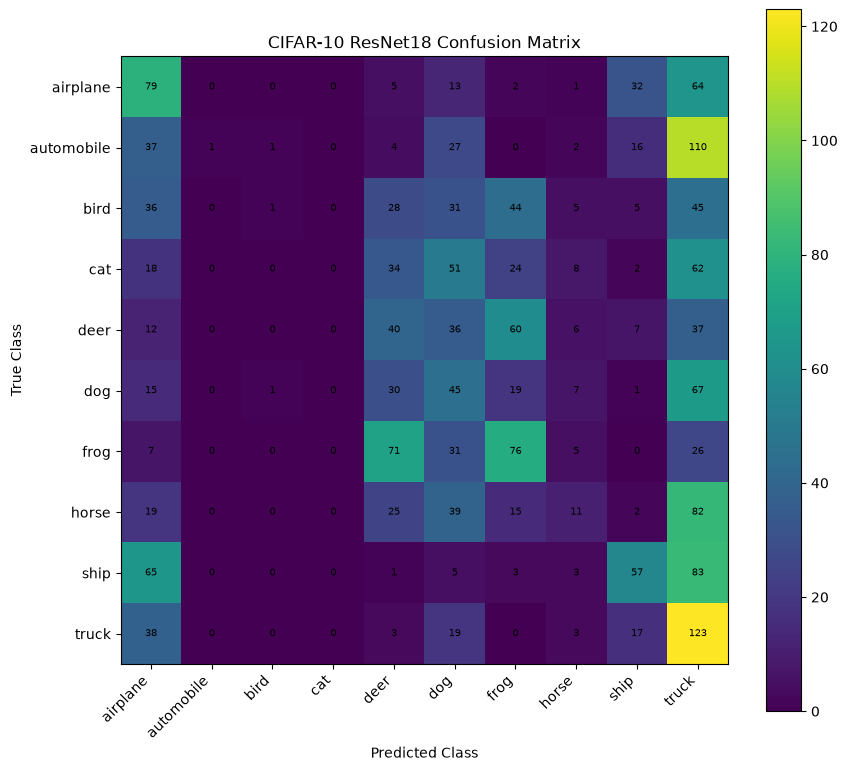

===== 클래스별 정확도 =====


In [23]:
confusion_matrix = build_confusion_matrix(test_labels, test_predictions)

plt.figure(figsize=(9, 8))

plt.imshow(confusion_matrix.numpy())

plt.colorbar()

plt.xticks(range(10), class_names, rotation=45, ha="right")

plt.yticks(range(10), class_names)

plt.xlabel("Predicted Class")

plt.ylabel("True Class")

plt.title("CIFAR-10 ResNet18 Confusion Matrix")

for row in range(10):
    for column in range(10):
        plt.text(
            column,
            row,
            confusion_matrix[row, column].item(),
            ha="center",
            va="center",
            fontsize=7,
        )

plt.tight_layout()

plt.show()

class_correct = confusion_matrix.diag()

class_total = confusion_matrix.sum(dim=1)

class_accuracy = class_correct.float() / class_total.clamp_min(1)

print("===== 클래스별 정확도 =====")

### 22) 클래스별 정확도 확인

In [24]:
for index, accuracy in enumerate(class_accuracy):
    print(f"{class_names_ko[index]:4s}: {accuracy.item() * 100:6.2f}%")

비행기 :  40.31%
자동차 :   0.51%
새   :   0.51%
고양이 :   0.00%
사슴  :  20.20%
개   :  24.32%
개구리 :  35.19%
말   :   5.70%
배   :  26.27%
트럭  :  60.59%


### 23) 클래스별 정확도 그래프와 주요 혼동

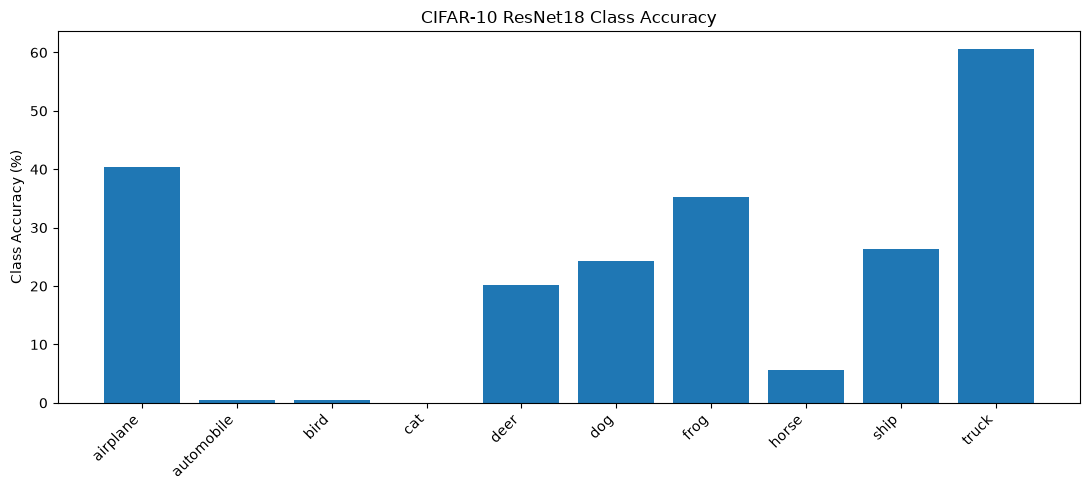

가장 많이 혼동한 방향: 자동차 → 트럭
혼동 이미지 수: 110


In [25]:
plt.figure(figsize=(11, 5))

plt.bar(class_names, class_accuracy.numpy() * 100)

plt.xticks(rotation=45, ha="right")

plt.ylabel("Class Accuracy (%)")

plt.title("CIFAR-10 ResNet18 Class Accuracy")

plt.tight_layout()

plt.show()

confusion_errors = confusion_matrix.clone()

confusion_errors.fill_diagonal_(0)

flat_index = confusion_errors.argmax().item()

true_index = flat_index // 10

predicted_index = flat_index % 10

print(
    "가장 많이 혼동한 방향:",
    f"{class_names_ko[true_index]} → {class_names_ko[predicted_index]}",
)

print("혼동 이미지 수:", confusion_errors[true_index, predicted_index].item())

### 24) 테스트 예측 결과 시각화

예측 이미지에서 다음 정보를 함께 확인합니다.

- 실제 클래스
- 예측 클래스
- 예측 확률

정답 여부뿐 아니라 모델이 얼마나 확신했는지도 확인합니다.

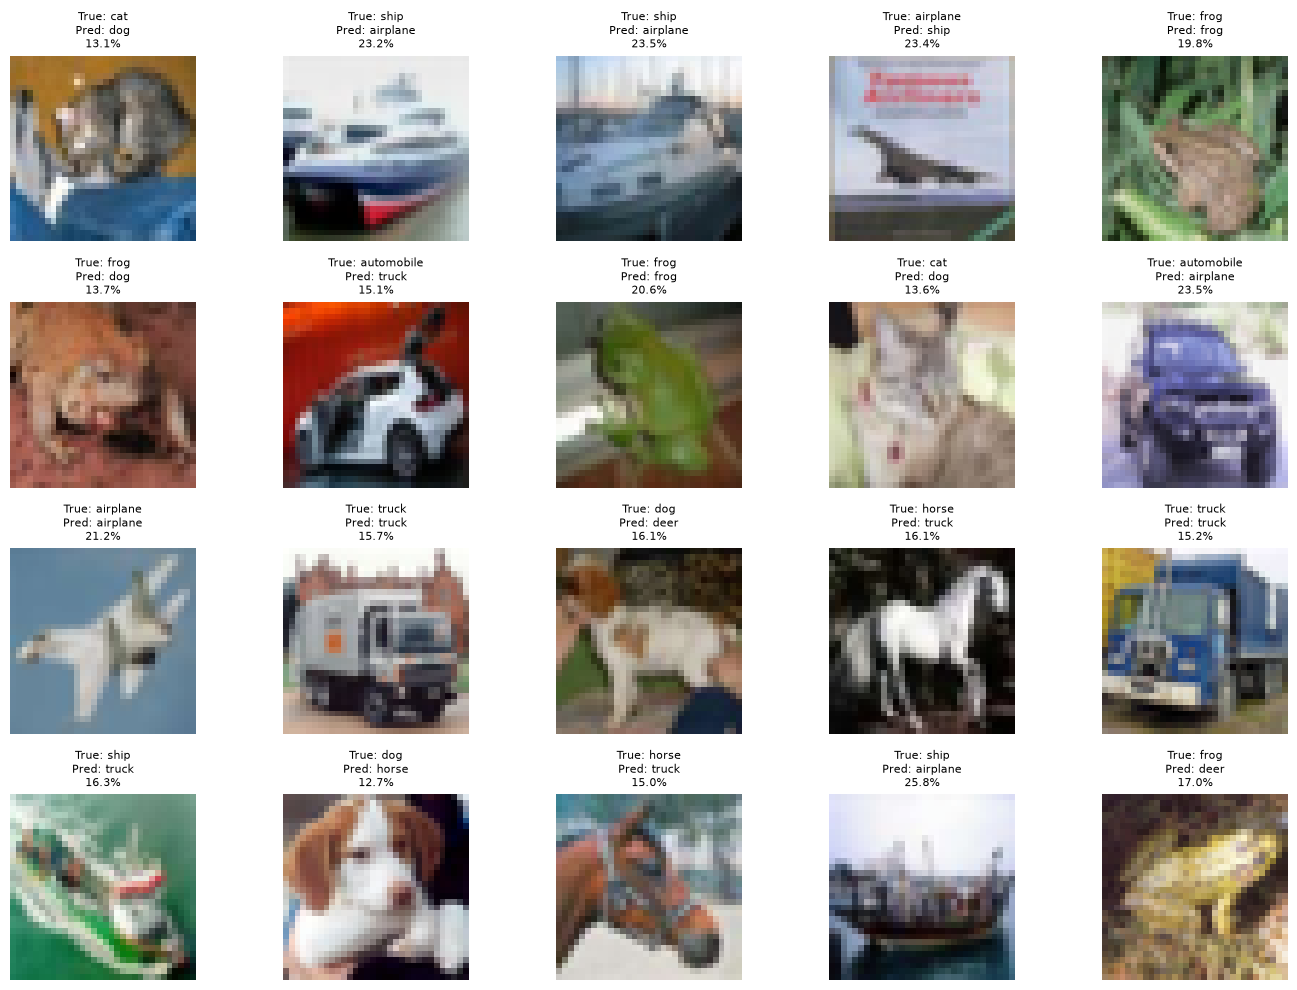

In [26]:
num_examples = min(20, len(test_images))

plt.figure(figsize=(14, 10))

for index in range(num_examples):
    image = denormalize_image(test_images[index]).permute(1, 2, 0)
    true_label = test_labels[index].item()
    predicted_label = test_predictions[index].item()
    confidence = test_confidences[index].item()

    plt.subplot(4, 5, index + 1)
    plt.imshow(image)
    plt.title(
        f"True: {class_names[true_label]}\n"
        f"Pred: {class_names[predicted_label]}\n"
        f"{confidence * 100:.1f}%",
        fontsize=8,
    )
    plt.axis("off")

plt.tight_layout()

plt.show()

### 25) 확신도가 높은 오답

오답 이미지를 직접 확인하면 숫자만으로는 알기 어려운 문제를 발견할 수 있습니다.

- 객체가 작거나 흐린 이미지
- 배경과 객체의 색상이 비슷한 이미지
- 클래스 사이의 외형이 비슷한 이미지
- 모델이 높은 확률로 잘못 판단한 이미지

특히 높은 확률로 틀린 이미지는 모델이 잘못된 특징을 강하게 학습했을 가능성을 보여줍니다.

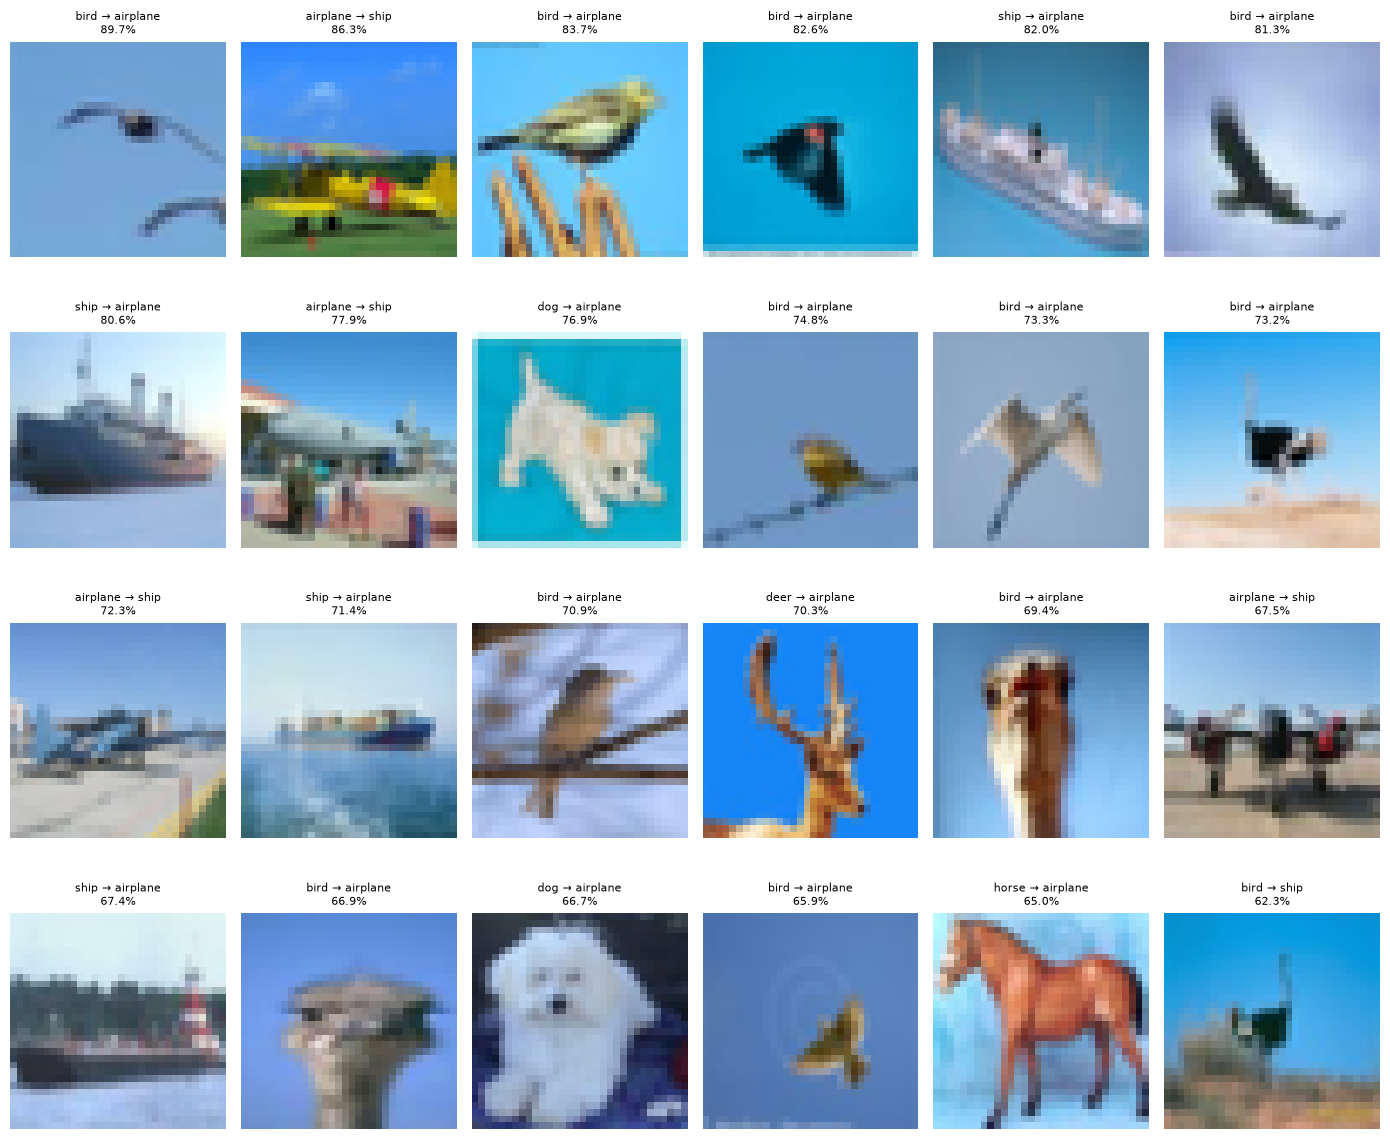

전체 오답 수: 1567


In [27]:
incorrect_indices = torch.where(test_predictions != test_labels)[0]

if len(incorrect_indices) > 0:
    # 확신도가 높은 오답부터 정렬
    error_confidences = test_confidences[incorrect_indices]
    order = torch.argsort(error_confidences, descending=True)
    selected_indices = incorrect_indices[order]

    num_errors = min(24, len(selected_indices))
    plt.figure(figsize=(14, 12))

    for index in range(num_errors):
        data_index = selected_indices[index].item()

        image = denormalize_image(test_images[data_index]).permute(1, 2, 0)
        true_label = test_labels[data_index].item()
        predicted_label = test_predictions[data_index].item()
        confidence = test_confidences[data_index].item()

        plt.subplot(4, 6, index + 1)
        plt.imshow(image)
        plt.title(
            f"{class_names[true_label]} → {class_names[predicted_label]}\n"
            f"{confidence * 100:.1f}%",
            fontsize=8,
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()

print("전체 오답 수:", len(incorrect_indices))

### 26) 저장 모델 복원 확인

체크포인트에는 모델 가중치와 실습에 필요한 설정을 함께 저장했습니다.

```text
같은 ResNet18 구조 생성
→ 체크포인트 불러오기
→ model_state_dict 적용
→ model.eval()
→ 예측
```

`weights_only=True`를 사용하여 텐서와 단순 설정값으로 구성된 체크포인트를 안전한 방식으로 불러옵니다.

In [28]:
loaded_checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=True,
)

restored_model = create_cifar10_resnet18(
    num_classes=loaded_checkpoint["num_classes"]
).to(device)

restored_model.load_state_dict(loaded_checkpoint["model_state_dict"])

restored_model.eval()

sample_images, sample_labels = next(iter(test_loader))

with torch.inference_mode():
    logits = restored_model(sample_images.to(device))
    predictions = logits.argmax(dim=1).cpu()

correct_count = (predictions == sample_labels).sum().item()

print("저장 모델:", loaded_checkpoint["model_name"])

print("최고 Epoch:", loaded_checkpoint["best_epoch"])

print(
    "최고 검증 정확도:",
    f"{loaded_checkpoint['best_validation_accuracy'] * 100:.2f}%",
)

print("첫 미니배치 정답 수:", correct_count, "/", len(sample_labels))

저장 모델: cifar10_resnet18
최고 Epoch: 3
최고 검증 정확도: 21.40%
첫 미니배치 정답 수: 25 / 128


## 핵심 정리

- `resnet18(weights=None)`은 사전학습 없이 CIFAR-10으로 처음부터 학습합니다.
- 32×32 입력에 맞게 첫 합성곱 계층을 조정하고 초기 MaxPool을 제거합니다.
- Residual 연결은 `y = F(x) + x`이며 shape가 다르면 Downsample로 맞춥니다.